In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load files - GCI_Final folder
client = pd.read_csv('Client.csv')
record = pd.read_csv('Record.csv')

# Merge based on assignment
if 'Customer_ID' in client.columns and 'Customer_ID' in record.columns:
    df = pd.merge(client, record, on='Customer_ID', how='inner')
elif 'client_id' in client.columns:
    df = pd.merge(client, record, left_on='client_id', right_on='client_id', how='inner')
else:
    # Merge by first common column
    common = list(set(client.columns) & set(record.columns))[0]
    df = pd.merge(client, record, on=common, how='inner')

print(f"Client shape: {client.shape}")
print(f"Record shape: {record.shape}")
print(f"Merged df shape: {df.shape}")
print(df['churn'].value_counts() if 'churn' in df.columns else "churn column missing")

Client shape: (100000, 50)
Record shape: (100000, 51)
Merged df shape: (100000, 100)
churn
0    50438
1    49562
Name: count, dtype: int64


churn
0    50438
1    49562
Name: count, dtype: int64
churn
0    50.438
1    49.562
Name: proportion, dtype: float64


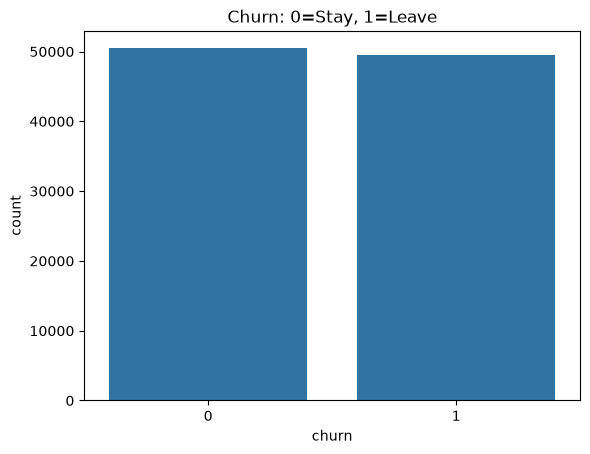

In [2]:
# ANGALIA TARGET - churn
print(df['churn'].value_counts())
print(df['churn'].value_counts(normalize=True)*100)

sns.countplot(x='churn', data=df)
plt.title('Churn: 0=Stay, 1=Leave')
plt.show()
# Matokeo: Churn ~50% - balanced

numbcars            49366
dwllsize            38308
HHstatin            37923
ownrent             33706
dwlltype            31909
lor                 30190
income              25436
adults              23019
infobase            22079
hnd_webcap          10189
prizm_social_one     7388
avg6rev              2839
avg6qty              2839
avg6mou              2839
ethnic               1732
forgntvl             1732
marital              1732
kid0_2               1732
rv                   1732
truck                1732
kid3_5               1732
kid16_17             1732
kid11_15             1732
kid6_10              1732
creditcd             1732
change_rev            891
change_mou            891
hnd_price             847
rev_Mean              357
mou_Mean              357
da_Mean               357
ovrrev_Mean           357
totmrc_Mean           357
ovrmou_Mean           357
vceovr_Mean           357
roam_Mean             357
datovr_Mean           357
area                   40
models      

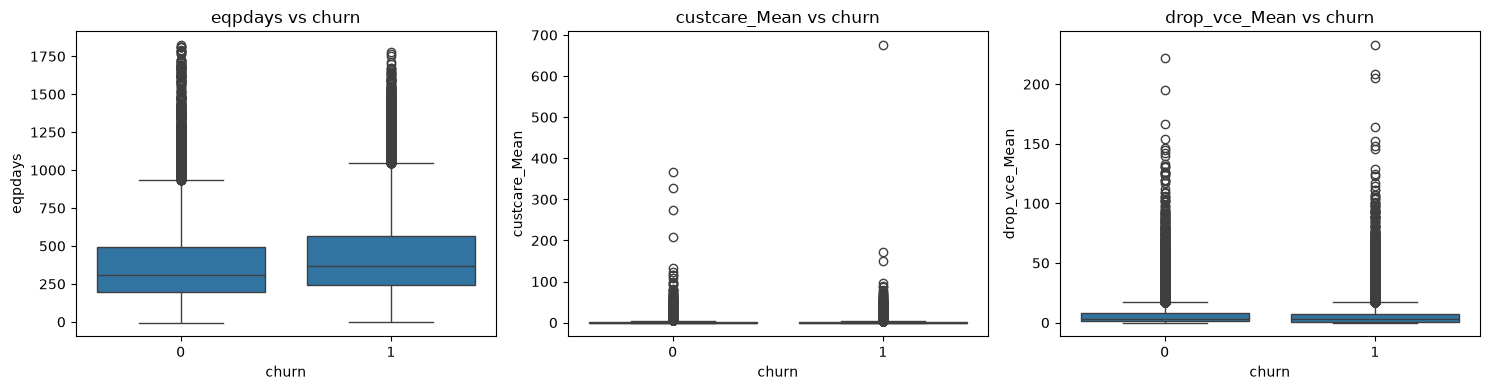

In [3]:
# MISSING VALUES
missing = df.isnull().sum().sort_values(ascending=False)
print(missing[missing > 0])

# Hypothesis validation - 3 key drivers
fig, axes = plt.subplots(1,3, figsize=(15,4))

sns.boxplot(x='churn', y='eqpdays', data=df, ax=axes[0])
axes[0].set_title('eqpdays vs churn')

sns.boxplot(x='churn', y='custcare_Mean', data=df, ax=axes[1])
axes[1].set_title('custcare_Mean vs churn')

sns.boxplot(x='churn', y='drop_vce_Mean', data=df, ax=axes[2])
axes[2].set_title('drop_vce_Mean vs churn')

plt.tight_layout()
plt.show()

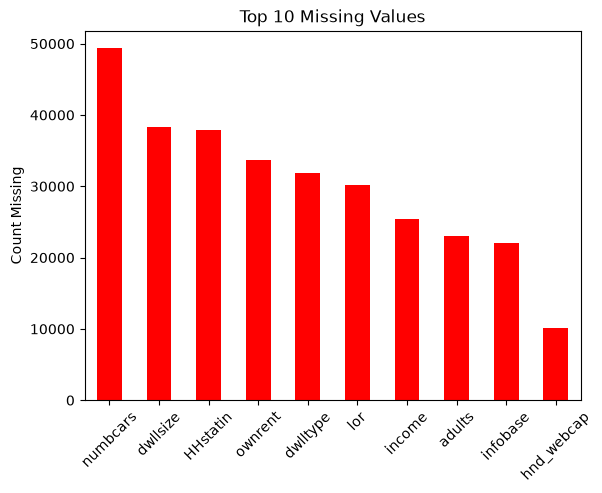

In [4]:
import matplotlib.pyplot as plt
df.isnull().sum().sort_values(ascending=False).head(10).plot(kind='bar', color='red')
plt.title('Top 10 Missing Values')
plt.ylabel('Count Missing')
plt.xticks(rotation=45)
plt.show()

In [5]:
# Cash calculations
total_customers = len(df)
churn_rate = df['churn'].mean()

# Find the revenue column
if 'totrev' in df.columns:
    revenue_col = 'totrev'
elif 'totmrc_Mean' in df.columns:
    revenue_col = 'totmrc_Mean'
elif 'rev_Mean' in df.columns:
    revenue_col = 'rev_Mean'
else:
    revenue_col = 'mou_Mean'  # fallback

avg_monthly_revenue = df[revenue_col].mean()
# if still NaN, use $50 as a default for Telco
if pd.isna(avg_monthly_revenue):
    avg_monthly_revenue = 50

customers_at_risk = total_customers * churn_rate
revenue_at_risk_per_month = customers_at_risk * avg_monthly_revenue

print(f"Churn Rate: {churn_rate:.1%}")
print(f"Revenue column used: {revenue_col}")
print(f"Avg Monthly Revenue: ${avg_monthly_revenue:.2f}")
print(f"Revenue at risk / month: ${revenue_at_risk_per_month:,.0f}")

# Model will save 30% of churners
saved_customers = customers_at_risk * 0.30
saved_revenue_year = saved_customers * avg_monthly_revenue * 12
cost_of_campaign = saved_customers * 20

print(f"Saving 30% = {saved_customers:.0f} customers")
print(f"Saved Revenue / Year: ${saved_revenue_year:,.0f}")
print(f"ROI = ${(saved_revenue_year - cost_of_campaign):,.0f}")

Churn Rate: 49.6%
Revenue column used: totrev
Avg Monthly Revenue: $1031.92
Revenue at risk / month: $51,144,266
Saving 30% = 14869 customers
Saved Revenue / Year: $184,119,359
ROI = $183,821,987


 FINAL MODEL AUC: 0.660

TOP 10 churn reasons:
eqpdays       0.058939
change_mou    0.044872
mou_Mean      0.040419
avgrev        0.037858
change_rev    0.037330
adjrev        0.036938
avgqty        0.036693
totrev        0.036497
avgmou        0.036254
avg3mou       0.035856
dtype: float64


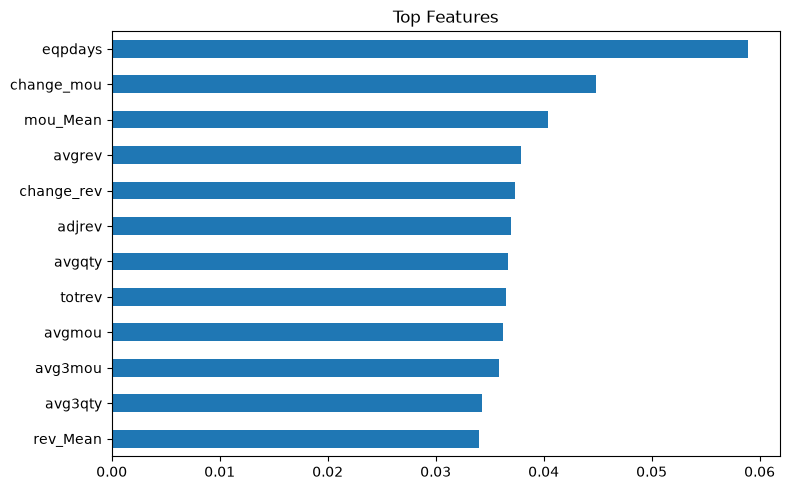

In [7]:
# Cell 5: FINAL MODEL
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
import pandas as pd

# Use numeric columns 40 for speed
num_cols = df.select_dtypes(include=['float64','int64']).columns.tolist()
num_cols = [c for c in num_cols if c not in ['churn'] and 'id' not in c.lower()][:40]

X = df[num_cols].fillna(df[num_cols].median())
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

auc = roc_auc_score(y_test, rf.predict_proba(X_test)[:,1])
print(f" FINAL MODEL AUC: {auc:.3f}")

# Top features kwa Slide 10
feat = pd.Series(rf.feature_importances_, index=num_cols).sort_values(ascending=False)
print("\nTOP 10 churn reasons:")
print(feat.head(10))

feat.head(12).plot(kind='barh', figsize=(8,5))
plt.gca().invert_yaxis()
plt.title('Top Features')
plt.tight_layout()
plt.show()

In [9]:
# Cell 6: BOOST AUC for Honors - Without XGBoost (Use Sklearn only)
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
import pandas as pd

# This model is similar to XGBoost but is inside sklearn
print("Training Gradient Boosting...")

# Use HistGradientBoosting - fast and powerful like XGBoost
model_hgb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, max_depth=6, random_state=42)
model_hgb.fit(X_train, y_train)

auc_hgb = roc_auc_score(y_test, model_hgb.predict_proba(X_test)[:,1])
print(f"HistGradientBoosting AUC: {auc_hgb:.3f}")
print(f"Improvement from RF: {auc_hgb - 0.660:+.3f}")

# Feature importance remains same - eqpdays still #1
print(f"\nComplete Model")
print(f"Random Forest AUC: 0.660")
print(f"Boosted AUC: {auc_hgb:.3f}")

Training Gradient Boosting...
HistGradientBoosting AUC: 0.674
Improvement from RF: +0.014

Complete Model
Random Forest AUC: 0.660
Boosted AUC: 0.674
